# 1MD049 Task 1 · Image Search and Retrieval
**DINOv3 ViT-S/16 vs. TinyCLIP ViT-22M/32 on Imagenette**

输入一张查询图，从图库中找出最相似的图片。用同一批查询和图库比较两个预训练模型。图库和查询分别从 Imagenette 的 `train` 和 `val` 取样。默认 10 个类别各取 **30 张图库图**和 **10 张查询图**，共 300 张图库图和 100 张查询图。类别标签用于分层抽样、评估和可视化。

### 在 Kaggle 上运行

1. 导入这个 `.ipynb`，在 Notebook 设置中将 **Internet** 设为 **On**，并选择可用的 **GPU**（例如 T4）。如果没有选择 GPU，代码会在 CPU 上运行。
2. 如果已有 DINOv3 权重，先通过 **Add Input** 添加文件，在下面填写 `DINOV3_WEIGHTS_PATH`，再点击 **Run All**。留空时会使用 timm 发布的 DINOv3 权重。Imagenette 和 TinyCLIP 会按原流程下载。
3. 图和 CSV 输出到 `/kaggle/working/imagenette_tinyclip_retrieval_results/`。已有 Imagenette 数据时，可将配置中的 `IMAGENETTE_PATH` 改成 Kaggle Input 里的压缩包路径，或含 `train/` 和 `val/` 的目录路径。
TinyCLIP 使用官方自动压缩版本 `TinyCLIP-auto-ViT-22M-32-Text-10M`，预训练权重为 LAION400M。图像编码器约 22M 参数，patch 为 32×32。DINOv3 当前配置约 21M 参数，patch 为 16×16。两者参数量接近，但训练数据、训练目标和 patch 大小不同。

如果在已经运行过旧版 CLIP 的会话中执行，请安装后重启会话，再运行全部单元。第一次运行需要联网从 GitHub 下载 TinyCLIP 实现和权重。也可把官方 `.pt` 权重添加为 Kaggle Input 并填写 `TINYCLIP_WEIGHTS_PATH`。


In [1]:
import subprocess
import sys

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "timm==1.0.22", "transformers>=4.56,<6", "ftfy", "regex", "huggingface_hub",
])
# The auto-pruned 22M model requires the official TinyCLIP fork of OpenCLIP.
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "--no-deps", "--force-reinstall",
    "git+https://github.com/wkcn/TinyCLIP.git@ad981bf308f007c4a47c1b34786cc90bbfd2c43c",
])
if "open_clip" in sys.modules:
    raise RuntimeError("Restart the notebook session after installation, then run all cells again.")


In [2]:
import os
from pathlib import Path

for root, folders, files in os.walk("/kaggle/input"):
    folder = Path(root)
    if {"train", "val"}.issubset(folders):
        print("已解压的数据集目录", folder)

    for name in sorted(files):
        if name.lower().endswith((".tgz", ".tar.gz", ".pth", ".pt", ".safetensors", ".bin")):
            print(folder / name)

已解压的数据集目录 /kaggle/input/datasets/shengkaichen/imagenette/imagenette2-160
/kaggle/input/datasets/shengkaichen/dinov3-vits16/dinov3_vits16.pth


## 1. 实验配置

固定随机种子。首次运行可以使用默认样本量。要扩大实验，把每类图片数调高，或用 `None` 选取对应分割的全部图片。使用全量数据会增加特征提取和排序的时间。


### 使用已有的 DINOv3 权重

在 Kaggle 上传权重为 Dataset，再用 Notebook 的 **Add Input** 添加它。复制 Input 中的完整路径。

| 权重来源 | `DINOV3_WEIGHTS_PATH` 填什么 |
|---|---|
| Meta 官网的原始权重，例如 `dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth` | 文件路径 |
| `timm/...` 的单文件权重，例如 `model.safetensors` 或 `pytorch_model.bin` | 文件路径 |
| Hugging Face `facebook/...` 的 Transformers 版 | 包含 `config.json` 和 `model.safetensors` 的目录路径。保留原有文件名。若有 `preprocessor_config.json`，也一并放入目录。 |

当前配置是 **ViT-S/16（LVD-1689M）**。如果 Meta 或 timm 的权重属于 **ViT-S/16** 或 **ViT-L/16**，还要把 `DINOV3_TIMM_MODEL` 改成对应的模型名，例如 `vit_small_patch16_dinov3.lvd1689m` 或 `vit_large_patch16_dinov3.lvd1689m`。Transformers 目录里的 `config.json` 会指定其架构。如果更换了权重，重新运行特征提取及后续单元，让图库与查询使用同一个模型。

In [3]:
import gc
import json
import shutil
import tarfile
import tempfile
from importlib.metadata import version
from pathlib import Path
from urllib.error import URLError
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import timm
import torch
import torch.nn.functional as F
from IPython.display import display
from PIL import Image, ImageOps
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms
from tqdm.auto import tqdm

SEED = 42
GALLERY_PER_CLASS = 30
QUERY_PER_CLASS = 10
BATCH_SIZE = 32
IMAGE_SIZE = 224
TOP_K = (1, 5, 10)

IMAGENETTE_URL = "https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz"
IMAGENETTE_PATH = "/kaggle/input/datasets/shengkaichen/imagenette/imagenette2-160"  # e.g. "/kaggle/input/my-data/imagenette2-160"
DATA_CACHE = Path(tempfile.gettempdir()) / "imagenette_retrieval_data"
WORKING_DIR = Path("/kaggle/working")
if not WORKING_DIR.is_dir():
    WORKING_DIR = Path.cwd()
OUTPUT_DIR = WORKING_DIR / "imagenette_tinyclip_retrieval_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Set this to the mounted .pth/.safetensors file or a Transformers model folder.
DINOV3_WEIGHTS_PATH = "/kaggle/input/datasets/shengkaichen/dinov3-vits16/dinov3_vits16.pth"
# DINOV3_WEIGHTS_PATH = "/kaggle/input/my-dinov3-weights/dinov3_vitb16_pretrain_lvd1689m-73cec8be.pth"
# Match this to the Meta or timm checkpoint. Transformers reads its own config.
# DINOV3_TIMM_MODEL = "vit_base_patch16_dinov3.lvd1689m"
DINOV3_TIMM_MODEL = "vit_small_patch16_dinov3.lvd1689m"

TINYCLIP_PRETRAINED = "LAION400M"
# Optional official .pt checkpoint mounted through Kaggle Add Input.
TINYCLIP_WEIGHTS_PATH = None

MODEL_IDS = {
    "DINOv3": f"timm/{DINOV3_TIMM_MODEL}",
    "TinyCLIP": "TinyCLIP-auto-ViT-22M-32-Text-10M",
}
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(DEVICE))
print("Output:", OUTPUT_DIR)

/usr/local/lib/python3.13/dist-packages/timm/models/layers/__init__.py:48: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


Device: cuda:0
GPU: Tesla T4
Output: /kaggle/working/imagenette_tinyclip_retrieval_results


## 2. 下载 Imagenette 并建立图库与查询集

`wnid` 是原始 ImageNet 类别目录名。两组模型共享同一份图片清单，保存在 `split_manifest.csv`。

In [4]:
CLASS_NAMES = {
    "n01440764": "tench",
    "n02102040": "English springer",
    "n02979186": "cassette player",
    "n03000684": "chain saw",
    "n03028079": "church",
    "n03394916": "French horn",
    "n03417042": "garbage truck",
    "n03425413": "gas pump",
    "n03445777": "golf ball",
    "n03888257": "parachute",
}
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}


def is_imagenette_root(path):
    return all(
        (path / split / wnid).is_dir()
        for split in ("train", "val")
        for wnid in CLASS_NAMES
    )


def load_imagenette_root():
    if IMAGENETTE_PATH is not None:
        source = Path(IMAGENETTE_PATH).expanduser().resolve()
        if is_imagenette_root(source):
            return source
        if not source.is_file():
            raise FileNotFoundError(
                f"Check IMAGENETTE_PATH: {source}. Set it to the Imagenette "
                "archive or the folder containing train/ and val/."
            )
    else:
        source = DATA_CACHE / "imagenette2-160.tgz"

    DATA_CACHE.mkdir(parents=True, exist_ok=True)
    if IMAGENETTE_PATH is None and not source.is_file():
        partial = source.with_suffix(".tgz.part")
        print("Downloading Imagenette 160 px...")
        try:
            with urlopen(IMAGENETTE_URL, timeout=60) as response:
                with partial.open("wb") as destination:
                    shutil.copyfileobj(response, destination, length=1024 * 1024)
            partial.replace(source)
        except (URLError, OSError) as exc:
            raise RuntimeError(
                "Imagenette download failed. Enable Internet in Kaggle or "
                "attach the archive and set IMAGENETTE_PATH."
            ) from exc
        finally:
            partial.unlink(missing_ok=True)

    # The cache key changes when the source archive changes.
    stat = source.stat()
    cache_key = f"{stat.st_size}-{stat.st_mtime_ns}"
    extracted_root = DATA_CACHE / f"imagenette2-160-{cache_key}"
    if is_imagenette_root(extracted_root):
        return extracted_root

    print("Extracting:", source.name)
    with tempfile.TemporaryDirectory(dir=DATA_CACHE) as staging:
        with tarfile.open(source, mode="r:*") as archive:
            archive.extractall(staging, filter="data")
        candidate = Path(staging) / "imagenette2-160"
        if not is_imagenette_root(candidate):
            raise ValueError("Expected imagenette2-160/train and imagenette2-160/val.")
        candidate.rename(extracted_root)
    return extracted_root


def select_images(root, split, purpose, per_class, seed):
    rng = np.random.default_rng(seed)
    records = []
    for wnid, name in CLASS_NAMES.items():
        files = sorted(
            path for path in (root / split / wnid).iterdir()
            if path.is_file() and path.suffix.lower() in IMAGE_SUFFIXES
        )
        count = len(files) if per_class is None else per_class
        if not 1 <= count <= len(files):
            raise ValueError(
                f"{split}/{wnid} has {len(files)} images. Requested {count}."
            )
        for index in rng.permutation(len(files))[:count]:
            path = files[index]
            records.append({
                "partition": purpose,
                "wnid": wnid,
                "class_name": name,
                "relative_path": path.relative_to(root).as_posix(),
                "path": path,
            })
    return pd.DataFrame(records).sample(frac=1, random_state=seed).reset_index(drop=True)

In [5]:
DATA_ROOT = load_imagenette_root()
gallery = select_images(DATA_ROOT, "train", "gallery", GALLERY_PER_CLASS, SEED)
queries = select_images(DATA_ROOT, "val", "query", QUERY_PER_CLASS, SEED + 1)
if len(gallery) < max(TOP_K):
    raise ValueError("Gallery must contain at least as many images as max(TOP_K).")

manifest = pd.concat([gallery, queries], ignore_index=True).drop(columns="path")
manifest.to_csv(OUTPUT_DIR / "split_manifest.csv", index=False)
print(f"Gallery: {len(gallery):,} | Queries: {len(queries):,}")
display(pd.crosstab(manifest["class_name"], manifest["partition"]))

Gallery: 300 | Queries: 100


partition,gallery,query
class_name,,
English springer,30,10
French horn,30,10
cassette player,30,10
chain saw,30,10
church,30,10
garbage truck,30,10
gas pump,30,10
golf ball,30,10
parachute,30,10


## 3. 提取整图向量

| 模型 | 用于检索的向量 |
|---|---|
| DINOv3 | 最后一层的全局 CLS token，当前 ViT-S/16 为 384 维 |
| TinyCLIP ViT-22M/32 | 经过视觉投影层的图像向量，512 维 |

两种模型统一用双三次插值把短边缩放到 224，再中心裁剪为 **224 × 224**。各自使用预训练对应的均值和标准差做输入归一化，TinyCLIP 使用官方返回的评估预处理。模型权重保持冻结，输出向量做 L2 归一化，这样向量点积就是余弦相似度。

In [6]:
def read_image(path):
    with Image.open(path) as image:
        return ImageOps.exif_transpose(image).convert("RGB")


def image_transform(mean, std):
    return transforms.Compose([
        transforms.Resize(
            IMAGE_SIZE, interpolation=transforms.InterpolationMode.BICUBIC
        ),
        transforms.CenterCrop(IMAGE_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(mean, std),
    ])


class ImagePaths(Dataset):
    def __init__(self, paths, transform):
        self.paths = list(paths)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        return self.transform(read_image(self.paths[index]))


def load_transformers_dinov3(folder):
    from transformers import AutoConfig, AutoModel

    config = AutoConfig.from_pretrained(folder, local_files_only=True)
    if config.model_type != "dinov3_vit":
        raise ValueError(f"Expected a DINOv3 ViT config, found {config.model_type!r}.")

    model, info = AutoModel.from_pretrained(
        folder, config=config, local_files_only=True, output_loading_info=True
    )
    problems = {
        name: values for name, values in info.items()
        if name in {"missing_keys", "unexpected_keys", "mismatched_keys", "error_msgs"}
        and values
    }
    if problems:
        details = ", ".join(f"{key}={list(values)[:3]}" for key, values in problems.items())
        raise ValueError(f"DINOv3 weights and config do not match ({details}).")

    model = model.eval().to(DEVICE)
    processor_config = folder / "preprocessor_config.json"
    settings = (
        json.loads(processor_config.read_text(encoding="utf-8"))
        if processor_config.is_file() else {}
    )
    preprocess = image_transform(
        settings.get("image_mean", (0.485, 0.456, 0.406)),
        settings.get("image_std", (0.229, 0.224, 0.225)),
    )
    print(f"DINOv3 weights loaded from {folder} ({config.hidden_size}-dim CLS)")

    def encode_batch(batch):
        return model(pixel_values=batch, return_dict=True).pooler_output

    return encode_batch, preprocess


def load_dinov3_encoder():
    model_options = dict(num_classes=0, global_pool="token", img_size=IMAGE_SIZE)
    if DINOV3_WEIGHTS_PATH is None:
        model = timm.create_model(f"hf-hub:{MODEL_IDS['DINOv3']}", pretrained=True, **model_options)
    else:
        path = Path(DINOV3_WEIGHTS_PATH).expanduser()
        if path.is_dir():
            if not (path / "config.json").is_file():
                raise FileNotFoundError(
                    f"No config.json in {path}. For Meta or timm weights, "
                    "set DINOV3_WEIGHTS_PATH to the weight file."
                )
            return load_transformers_dinov3(path)
        if not path.is_file():
            raise FileNotFoundError(
                f"DINOv3 weights not found: {path}. Add the Kaggle Input "
                "and copy the exact path into DINOV3_WEIGHTS_PATH."
            )

        suffix = path.suffix.lower()
        if suffix == ".safetensors":
            from safetensors.torch import load_file

            state_dict = load_file(str(path), device="cpu")
        elif suffix in {".pth", ".pt", ".bin"}:
            state_dict = torch.load(path, map_location="cpu", weights_only=True)
        else:
            raise ValueError(f"Unsupported DINOv3 weight file: {path.name}.")

        for key in ("model", "state_dict"):
            if isinstance(state_dict, dict) and isinstance(state_dict.get(key), dict):
                state_dict = state_dict[key]
        if not isinstance(state_dict, dict) or not state_dict:
            raise ValueError(f"Expected a model state_dict in {path.name}.")
        state_dict = {key.removeprefix("module."): value for key, value in state_dict.items()}

        if "embeddings.cls_token" in state_dict:
            raise ValueError(
                "This is a Transformers checkpoint. Set DINOV3_WEIGHTS_PATH "
                "to the folder with the weights and the matching config.json."
            )

        model = timm.create_model(DINOV3_TIMM_MODEL, pretrained=False, **model_options)
        if "storage_tokens" in state_dict:
            # Convert the key layout of the original Meta ViT checkpoint to timm.
            from timm.models.eva import checkpoint_filter_fn

            model_has_q_bias = "blocks.0.attn.q_bias" in model.state_dict()
            for key, value in state_dict.items():
                if not model_has_q_bias and key.endswith(".attn.qkv.bias"):
                    q, _, v = value.chunk(3)
                    if torch.any(q != 0) or torch.any(v != 0):
                        raise ValueError(
                            "The checkpoint has learned query/value biases. Set "
                            "DINOV3_TIMM_MODEL to the matching DINOv3 model with QKV bias."
                        )
            state_dict = checkpoint_filter_fn(state_dict, model)
        try:
            model.load_state_dict(state_dict, strict=True)
        except RuntimeError as exc:
            raise RuntimeError(
                f"{path.name} does not match {DINOV3_TIMM_MODEL}. "
                "Check the DINOv3 variant and the checkpoint source."
            ) from exc
        print(f"DINOv3 weights loaded from {path} ({DINOV3_TIMM_MODEL})")

    config = timm.data.resolve_model_data_config(model)
    preprocess = image_transform(config["mean"], config["std"])
    return model.eval().to(DEVICE), preprocess


def load_encoder(model_name):
    if model_name == "DINOv3":
        return load_dinov3_encoder()
    if model_name == "TinyCLIP":
        pretrained = TINYCLIP_PRETRAINED
        if TINYCLIP_WEIGHTS_PATH is not None:
            checkpoint = Path(TINYCLIP_WEIGHTS_PATH).expanduser()
            if not checkpoint.is_file():
                raise FileNotFoundError(f"TinyCLIP checkpoint not found: {checkpoint}")
            pretrained = str(checkpoint)
        if MODEL_IDS["TinyCLIP"] not in open_clip.list_models():
            raise RuntimeError("Install the TinyCLIP fork in the first cell and restart the session.")
        model, _, preprocess = open_clip.create_model_and_transforms(
            MODEL_IDS["TinyCLIP"], pretrained=pretrained,
        )
        model = model.eval().requires_grad_(False).to(DEVICE)
        image_parameters = sum(parameter.numel() for parameter in model.visual.parameters())
        print(f"TinyCLIP image encoder: {image_parameters:,} parameters")
        return model.encode_image, preprocess
    raise ValueError(f"Unknown encoder: {model_name}")

@torch.inference_mode()
def embed_images(model_name, paths, description):
    encode_batch, preprocess = load_encoder(model_name)
    loader = DataLoader(
        ImagePaths(paths, preprocess),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=DEVICE.type == "cuda",
    )
    parts = []
    for batch in tqdm(loader, desc=description, leave=False):
        batch = batch.to(DEVICE, non_blocking=DEVICE.type == "cuda")
        vectors = encode_batch(batch).float()
        parts.append(F.normalize(vectors, p=2, dim=1).cpu().numpy())

    features = np.concatenate(parts, axis=0)
    if not np.isfinite(features).all():
        raise ValueError(f"{model_name} returned non-finite features.")
    if not np.allclose(np.linalg.norm(features, axis=1), 1.0, atol=1e-4):
        raise ValueError(f"{model_name} returned zero or unnormalized features.")

    del encode_batch, batch, vectors, parts
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return features

In [7]:
paths = gallery["path"].tolist() + queries["path"].tolist()
gallery_features = {}
query_features = {}

for model_name in MODEL_IDS:
    features = embed_images(model_name, paths, f"{model_name} embeddings")
    gallery_features[model_name] = features[:len(gallery)]
    query_features[model_name] = features[len(gallery):]
    print(
        f"{model_name}: gallery {gallery_features[model_name].shape}, "
        f"queries {query_features[model_name].shape}"
    )

run_info = {
    "seed_gallery": SEED,
    "seed_query": SEED + 1,
    "gallery_per_class": GALLERY_PER_CLASS,
    "query_per_class": QUERY_PER_CLASS,
    "gallery_size": len(gallery),
    "query_size": len(queries),
    "input_size": IMAGE_SIZE,
    "models": {
        **MODEL_IDS,
        "DINOv3": str(DINOV3_WEIGHTS_PATH or MODEL_IDS["DINOv3"]),
    },
    "tinyclip_pretrained": str(TINYCLIP_WEIGHTS_PATH or TINYCLIP_PRETRAINED),
    "dinov3_embedding_dim": int(gallery_features["DINOv3"].shape[1]),
    "packages": {
        name: version(name)
        for name in ("torch", "torchvision", "timm", "open-clip-torch", "numpy", "scikit-learn")
    },
}
(OUTPUT_DIR / "run_info.json").write_text(json.dumps(run_info, indent=2), encoding="utf-8")

`q_bias` is not an nn.Parameter
`q_bias` is not an nn.Parameter
`q_bias` is not an nn.Parameter
`q_bias` is not an nn.Parameter
`q_bias` is not an nn.Parameter
`q_bias` is not an nn.Parameter
`q_bias` is not an nn.Parameter
`q_bias` is not an nn.Parameter
`q_bias` is not an nn.Parameter
`q_bias` is not an nn.Parameter
`q_bias` is not an nn.Parameter
`q_bias` is not an nn.Parameter
DINOv3 weights loaded from /kaggle/input/datasets/shengkaichen/dinov3-vits16/dinov3_vits16.pth (vit_small_patch16_dinov3.lvd1689m)


DINOv3 embeddings:   0%|          | 0/13 [00:00<?, ?it/s]

DINOv3: gallery (300, 384), queries (100, 384)


100%|████████████████████████████████████████| 114M/114M [00:00<00:00, 266MiB/s]
/usr/local/lib/python3.13/dist-packages/open_clip/model.py:1316: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  dst[slices].copy_(src)


TinyCLIP image encoder: 22,024,993 parameters


TinyCLIP embeddings:   0%|          | 0/13 [00:00<?, ?it/s]

TinyCLIP: gallery (300, 512), queries (100, 512)


575

## 4. 比较检索指标

对每张查询图，图库中**同类别**的图片都算 relevant。用余弦相似度从高到低排序。表中各指标都先按查询图计算，再对所有查询取平均。

- **Precision@K** 衡量前 K 张结果中有多少比例与查询图同类。
- **Recall@K** 衡量图库中全部同类图片，有多少比例出现在前 K 张。在默认设置下，每类有 30 张图库图，因此 Recall@10 的上限是 10/30。
- **mAP** 是所有查询图的 AP 的均值。每张图的 AP 会在完整排名中，只对命中同类图的位置计算 Precision，再取平均。把同类图排得更靠前，AP 就更高。

报告可以用 mAP 概括全排名表现，并用 Precision@5 解释用户看到的前五个结果。

In [8]:
def retrieval_metrics(query_vectors, index_vectors, query_labels, index_labels, k_values):
    query_labels = np.asarray(query_labels)
    index_labels = np.asarray(index_labels)
    if not np.isin(query_labels, index_labels).all():
        raise ValueError("Every query class must have relevant images in the gallery.")

    ranks = np.arange(1, len(index_labels) + 1)
    results = []
    # Process queries in blocks so a full-dataset run uses less memory.
    for start in range(0, len(query_labels), 128):
        stop = start + 128
        scores = query_vectors[start:stop] @ index_vectors.T
        order = np.argsort(-scores, axis=1, kind="stable")
        relevant = index_labels[order] == query_labels[start:stop, None]
        hits = relevant.cumsum(axis=1)
        total_relevant = hits[:, -1]
        precision = hits / ranks
        block = {"AP": (precision * relevant).sum(axis=1) / total_relevant}
        for k in k_values:
            block[f"Precision@{k}"] = precision[:, k - 1]
            block[f"Recall@{k}"] = hits[:, k - 1] / total_relevant
        results.append(pd.DataFrame(block))
    return pd.concat(results, ignore_index=True)

,mAP,Precision@1,Recall@1,Precision@5,Recall@5,Precision@10,Recall@10
model,,,,,,,
DINOv3,0.788,0.98,0.0327,0.910,0.1517,0.890,0.2967
TinyCLIP,0.845,0.97,0.0323,0.956,0.1593,0.941,0.3137


model,DINOv3,TinyCLIP
class_name,,
cassette player,0.6436,0.6842
tench,0.9434,0.9619
English springer,0.8872,0.9277
French horn,0.9817,0.9352
parachute,0.7431,0.8663
garbage truck,0.9234,0.8947
gas pump,0.8207,0.7511
chain saw,0.5905,0.5204
golf ball,0.9560,0.9840


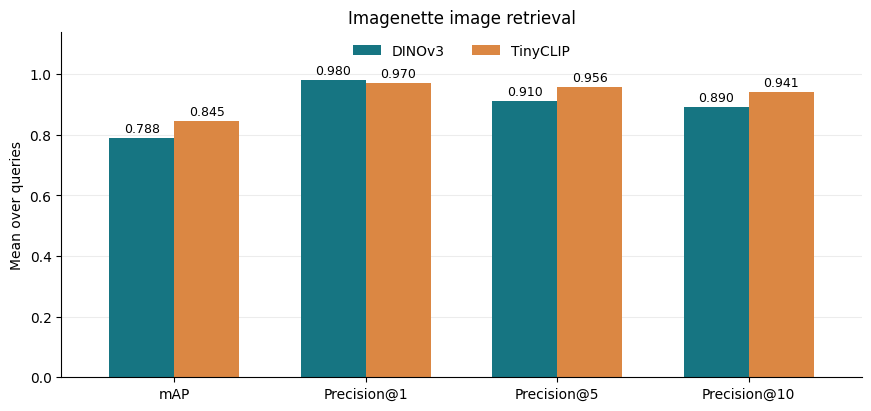

In [9]:
metric_columns = ["AP"] + [
    f"{metric}@{k}" for k in TOP_K for metric in ("Precision", "Recall")
]
query_tables = []
for model_name in MODEL_IDS:
    scores = retrieval_metrics(
        query_features[model_name], gallery_features[model_name],
        queries["wnid"], gallery["wnid"], TOP_K,
    )
    query_info = queries[["relative_path", "class_name"]].copy()
    query_info.insert(0, "model", model_name)
    query_tables.append(pd.concat([query_info, scores], axis=1))

per_query = pd.concat(query_tables, ignore_index=True)
summary = (
    per_query.groupby("model", sort=False)[metric_columns]
    .mean().rename(columns={"AP": "mAP"})
)
per_class = (
    per_query.groupby(["class_name", "model"], sort=False)[metric_columns]
    .mean().rename(columns={"AP": "mAP"})
)
display(summary.round(4))
display(per_class["mAP"].unstack().reindex(columns=list(MODEL_IDS)).round(4))

summary.to_csv(OUTPUT_DIR / "metrics_summary.csv")
per_class.to_csv(OUTPUT_DIR / "metrics_by_class.csv")
per_query.to_csv(OUTPUT_DIR / "metrics_per_query.csv", index=False)

plot_metrics = ["mAP"] + [f"Precision@{k}" for k in TOP_K]
fig, ax = plt.subplots(figsize=(8.6, 4.0), layout="constrained")
summary[plot_metrics].T.plot.bar(
    ax=ax, color=["#167582", "#db8743"], rot=0, width=0.68,
)
ax.set(title="Imagenette image retrieval", ylabel="Mean over queries", ylim=(0, 1.14))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.24)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.0), ncols=2, frameon=False)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=9)
fig.savefig(OUTPUT_DIR / "metrics_comparison.png", dpi=180)
plt.show()

## 5. 可视化两个特征空间

在同一批图上，分别对两个模型的 L2 归一化向量做 PCA 和 t-SNE。同一种颜色始终代表同一个类别。可以观察某个类别是否形成若干局部簇，以及哪些类别在二维图中有混合。两幅图各自拟合降维，坐标和簇间距离没有共同尺度。定量检索指标仍使用原始高维特征。

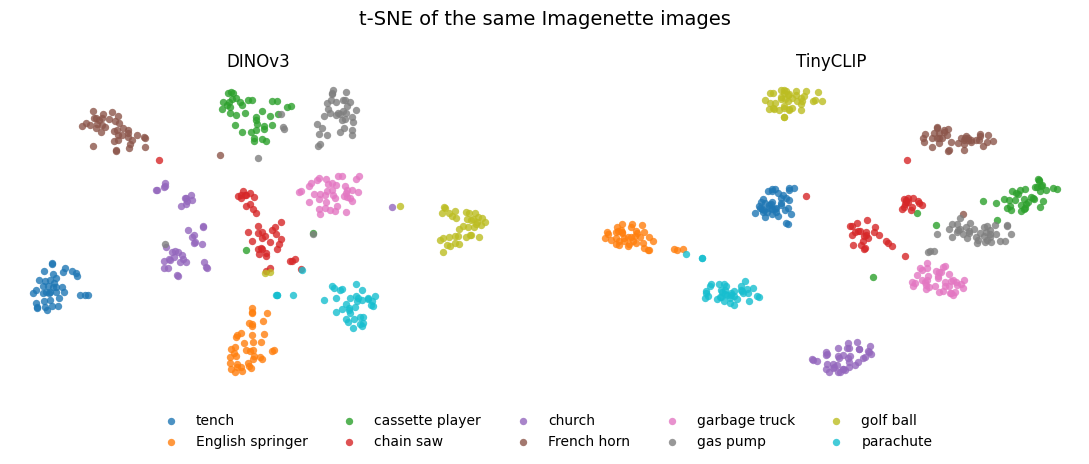

In [10]:
combined_labels = pd.concat([gallery["wnid"], queries["wnid"]], ignore_index=True).to_numpy()
plot_rng = np.random.default_rng(SEED)
plot_indices = np.concatenate([
    plot_rng.permutation(np.flatnonzero(combined_labels == wnid))[:40]
    for wnid in CLASS_NAMES
])
plot_labels = combined_labels[plot_indices]
colors = dict(zip(CLASS_NAMES, plt.get_cmap("tab10").colors))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.7))
for ax, model_name in zip(axes, MODEL_IDS):
    combined_vectors = np.concatenate([gallery_features[model_name], query_features[model_name]])
    plot_vectors = combined_vectors[plot_indices]
    n_pca = min(50, len(plot_indices) - 1, plot_vectors.shape[1])
    reduced = PCA(n_components=n_pca, random_state=SEED).fit_transform(plot_vectors)
    projection = TSNE(
        n_components=2,
        perplexity=min(30.0, float(len(plot_indices) - 1)),
        init="pca",
        learning_rate="auto",
        random_state=SEED,
    ).fit_transform(reduced)

    for wnid, name in CLASS_NAMES.items():
        members = plot_labels == wnid
        ax.scatter(
            projection[members, 0], projection[members, 1],
            label=name, color=colors[wnid], s=28, alpha=0.80, linewidths=0,
        )
    ax.set(title=model_name, xticks=[], yticks=[])
    ax.spines[:].set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 0.02), ncol=5, frameon=False)
fig.suptitle("t-SNE of the same Imagenette images", fontsize=14)
fig.subplots_adjust(top=0.84, bottom=0.18, left=0.035, right=0.965, wspace=0.15)
fig.savefig(OUTPUT_DIR / "embedding_tsne.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. 查看两种方法的 Top-5 检索结果

默认显示一个固定种子选出的查询，以及两个模型 AP 差值的最大和最小案例。绿色的结果标题表示类别匹配，红色表示其他类别。缩略图下的数字是该模型的余弦相似度，用于看各自的排序。

In [11]:
def show_retrieval(path, vectors, query_wnid=None, caption=None, filename=None, k=5):
    fig, axes = plt.subplots(
        len(MODEL_IDS), k + 1, figsize=(2.13 * (k + 1), 4.6),
        layout="constrained", squeeze=False,
    )
    query_image = read_image(path)
    query_name = "Custom image" if query_wnid is None else CLASS_NAMES[query_wnid]

    for row, model_name in enumerate(MODEL_IDS):
        scores = gallery_features[model_name] @ vectors[model_name]
        best = np.argsort(-scores, kind="stable")[:k]
        axes[row, 0].imshow(query_image)
        axes[row, 0].set_title(f"{model_name} · query\n{query_name}", fontsize=10)
        for rank, index in enumerate(best, start=1):
            item = gallery.iloc[index]
            ax = axes[row, rank]
            ax.imshow(read_image(item["path"]))
            color = "#333333"
            if query_wnid is not None:
                color = "#18704a" if item["wnid"] == query_wnid else "#a7333e"
            ax.set_title(
                f"{rank}. {item['class_name']}\ncos {scores[index]:.3f}",
                color=color, fontsize=9,
            )

    for ax in axes.flat:
        ax.axis("off")
    if caption:
        fig.suptitle(caption, fontsize=13)
    if filename:
        fig.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()

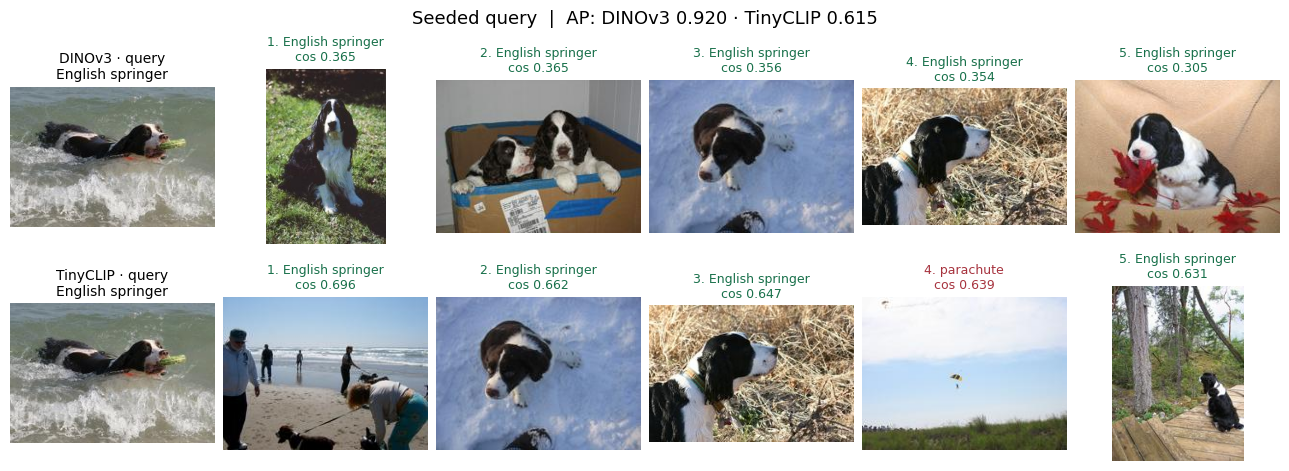

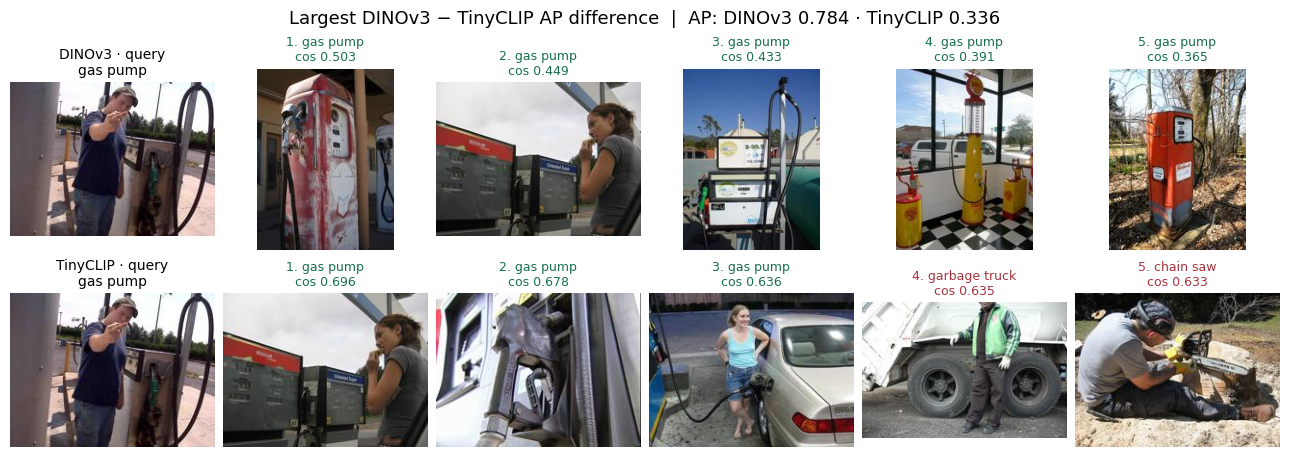

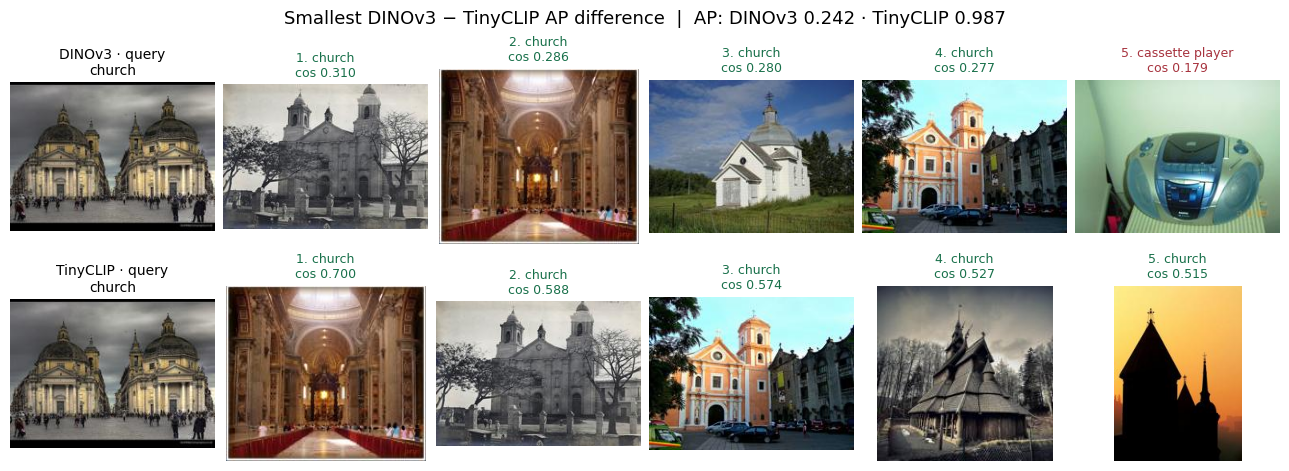

In [12]:
ap = per_query.pivot(index="relative_path", columns="model", values="AP")
ap = ap.reindex(queries["relative_path"])
ap_difference = (ap["DINOv3"] - ap["TinyCLIP"]).to_numpy()
examples = {
    "Seeded query": int(np.random.default_rng(SEED).integers(len(queries))),
    "Largest DINOv3 − TinyCLIP AP difference": int(ap_difference.argmax()),
    "Smallest DINOv3 − TinyCLIP AP difference": int(ap_difference.argmin()),
}
shown = set()
for title, index in examples.items():
    if index in shown:
        continue
    shown.add(index)
    query = queries.iloc[index]
    caption = (
        f"{title}  |  AP: DINOv3 {ap.iloc[index]['DINOv3']:.3f} · "
        f"TinyCLIP {ap.iloc[index]['TinyCLIP']:.3f}"
    )
    show_retrieval(
        query["path"],
        {name: query_features[name][index] for name in MODEL_IDS},
        query_wnid=query["wnid"], caption=caption,
        filename=f"retrieval_query_{index:03d}.png",
    )

## 7. 可选实验 · 用自己的图片搜索

把一张图片作为 Kaggle Input 添加到 Notebook。将 `CUSTOM_QUERY_PATH` 改成该图片的完整路径，然后运行下一格。它会用同一个 Imagenette 图库返回两个模型各自的前五个结果。

In [13]:
CUSTOM_QUERY_PATH = None  # e.g. "/kaggle/input/my-query/golf_ball.jpg"

if CUSTOM_QUERY_PATH is not None:
    query_path = Path(CUSTOM_QUERY_PATH).expanduser().resolve()
    if not query_path.is_file():
        raise FileNotFoundError(f"Query image not found: {query_path}")
    vectors = {
        name: embed_images(name, [query_path], f"{name} custom query")[0]
        for name in MODEL_IDS
    }
    show_retrieval(
        query_path, vectors,
        caption=f"Custom query · {query_path.name}",
        filename="retrieval_custom_query.png",
    )

## 8. 课上可以讨论什么

- 比较两个模型的 **mAP** 和 **Precision@5**，从分类别表中挑一个差距较大的类，再结合实际检索图说明差异。
- DINOv3 的训练来自图像自监督，TinyCLIP 通过图像与文字对齐训练。观察相同类别里外观差异很大的图如何排序，也看看外观类似的不同类别是否容易混在一起。TinyCLIP 还支持文本搜图，本实验只测以图搜图。
- Imagenette 的类别标签衡量的是**同类检索**。同类图片可能是不同实例。把这个流程迁移到医疗图像时，需要按任务定义相关性，例如相同解剖部位或相同类型的病灶。

### References

- [Imagenette dataset · fastai](https://github.com/fastai/imagenette)
- [DINOv3 paper](https://arxiv.org/abs/2508.10104) · [DINOv3 weights used here](https://huggingface.co/timm/vit_small_patch16_dinov3.lvd1689m)
- [TinyCLIP paper](https://arxiv.org/abs/2309.12314) · [TinyCLIP weights and implementation](https://github.com/wkcn/TinyCLIP) · [OpenCLIP](https://github.com/mlfoundations/open_clip)